In [13]:
import pandas as pd
import matplotlib.pyplot as plot
import os

# Check if the file exists before reading
file_path = '../messy_data_2000_rows.xlsx'
if not os.path.exists(file_path):
    # If it is not in the parent directory, check the current directory
    file_path = 'messy_data_2000_rows.xlsx'

try:
    df = pd.read_excel(file_path)
    print("✅ ਫਾਈਲ ਸਫਲਤਾਪੂਰਵਕ ਲੋਡ ਹੋ ਗਈ ਹੈ!")
except Exception as e:
    print(f"❌ ਫਾਈਲ ਲੋਡ ਕਰਨ ਵਿੱਚ ਸਮੱਸਿਆ ਆਈ: {e}")
    # Fallback to creating a dummy dataframe if file is missing, so code doesn't crash completely
    df = pd.DataFrame(columns=['Order ID', 'Product', 'Order Date', 'Quantiy', 'Unit Price', 'Customer Name', 'City', 'Category', 'Payment Method', 'Status', 'Phone', 'Email'])

print(df.head())
print(df.dtypes)
print(df.isnull().sum())
print(df.duplicated().sum())

df_clean = df.drop_duplicates().copy()
df_clean = df_clean.dropna(subset=['Order ID', 'Product'])

df_clean['Order Date']= pd.to_datetime(df_clean['Order Date'], dayfirst=True, errors='coerce')
df_clean['Quantiy'] = pd.to_numeric(df_clean['Quantiy'], errors='coerce')
df_clean['Unit Price'] = pd.to_numeric(df_clean['Unit Price'], errors='coerce')

# Corrected the typo 'df_clen' to 'df_clean' and 'Quantiy' to match the column name
# Also handle the renaming of the column 'Quantiy' to 'Quantity' for calculation
df_clean['Quantity'] = df_clean['Quantiy'].fillna(0) # filling missing quantity with 0
df_clean['Unit Price'] = df_clean['Unit Price'].fillna(df_clean['Unit Price'].median() if not df_clean['Unit Price'].isnull().all() else 0)

# 6. ਬਾਕੀ ਖਾਲੀ ਨਾਮ, ਸ਼ਹਿਰ, ਫ਼ੋਨ, ਈਮੇਲ ਦੀ ਥਾਂ 'Unknown' ਭਰਨਾ
text_cols = ['Customer Name', 'City', 'Category', 'Payment Method', 'Status', 'Phone', 'Email']
for col in text_cols:
    if col in df_clean.columns:
        df_clean[col] = df_clean[col].fillna('Unknown')

# 7. ਕੁੱਲ ਬਿੱਲ (Total_Sales) ਦਾ ਨਵਾਂ ਕਾਲਮ ਬਣਾਉਣਾ
df_clean['Total_Sales'] = df_clean['Quantity'] * df_clean['Unit Price']

print("✅ ਡਾਟਾ ਪੂਰੀ ਤਰ੍ਹਾਂ ਸਾਫ਼ ਹੋ ਗਿਆ ਹੈ!")
print(f"ਸਾਫ਼ ਲਾਈਨਾਂ ਦੀ ਗਿਣਤੀ: {len(df_clean)}")
print("\n--- ਹੁਣ ਖਾਲੀ ਖਾਨਿਆਂ ਦੀ ਜਾਂਚ (ਸਾਰੇ 0 ਹੋਣੇ ਚਾਹੀਦੇ ਹਨ) ---")
print(df_clean.isnull().sum())

# ਜਦੋਂ ਤੁਸੀਂ ਇਹ Data Cleaning ਕੋਡ ਚਲਾ ਲਵੋ, ਤਾਂ ਹੇਠਾਂ ਆਏ ਨਤੀਜੇ ਦੀ ਫੋਟੋ ਭੇਜੋ—ਫਿਰ ਅਸੀਂ ਇਸ ਸਾਫ਼ ਕੀਤੇ ਡਾਟਾ ਤੋਂ Agentic AI ਵਪਾਰਕ ਸਲਾਹਕਾਰ (Business AI Agent) ਬਣਾਵਾਂਗੇ ਜੋ ਕੰਪਨੀ ਦੀ ਵਿਕਰੀ ਵਧਾਉਣ ਦੇ ਸੁਝਾਅ ਦੇਵੇਗਾ?








❌ ਫਾਈਲ ਲੋਡ ਕਰਨ ਵਿੱਚ ਸਮੱਸਿਆ ਆਈ: [Errno 2] No such file or directory: 'messy_data_2000_rows.xlsx'
Empty DataFrame
Columns: [Order ID, Product, Order Date, Quantiy, Unit Price, Customer Name, City, Category, Payment Method, Status, Phone, Email]
Index: []
Order ID          object
Product           object
Order Date        object
Quantiy           object
Unit Price        object
Customer Name     object
City              object
Category          object
Payment Method    object
Status            object
Phone             object
Email             object
dtype: object
Order ID          0
Product           0
Order Date        0
Quantiy           0
Unit Price        0
Customer Name     0
City              0
Category          0
Payment Method    0
Status            0
Phone             0
Email             0
dtype: int64
0
✅ ਡਾਟਾ ਪੂਰੀ ਤਰ੍ਹਾਂ ਸਾਫ਼ ਹੋ ਗਿਆ ਹੈ!
ਸਾਫ਼ ਲਾਈਨਾਂ ਦੀ ਗਿਣਤੀ: 0

--- ਹੁਣ ਖਾਲੀ ਖਾਨਿਆਂ ਦੀ ਜਾਂਚ (ਸਾਰੇ 0 ਹੋਣੇ ਚਾਹੀਦੇ ਹਨ) ---
Order ID          0
Product           0
Order Date        0
Qu

In [14]:
from google.colab import files
import os

print("ਕਿਰਪਾ ਕਰਕੇ 'messy_data_2000_rows.xlsx' ਫਾਈਲ ਅਪਲੋਡ ਕਰੋ:")
uploaded = files.upload()

for fn in uploaded.keys():
    print('User uploaded file "{name}" with length {length} bytes'.format(
        name=fn, length=len(uploaded[fn])))


ਕਿਰਪਾ ਕਰਕੇ 'messy_data_2000_rows.xlsx' ਫਾਈਲ ਅਪਲੋਡ ਕਰੋ:


Saving messy_data_2000_rows.xlsx to messy_data_2000_rows.xlsx
User uploaded file "messy_data_2000_rows.xlsx" with length 160191 bytes


In [15]:
from google import genai

# 1. ਆਪਣੀ API Key
API_KEY = "ਆਪਣੀ ਕੀਅ ਸਮਲ ਕਰੋ"
client = genai.Client(api_key=API_KEY)

# 2. ਸਾਫ਼ ਕੀਤੇ ਡਾਟਾ (df_clean) ਵਿੱਚੋਂ ਕੰਪਨੀ ਦੀ ਅਸਲੀ ਕਮਾਈ ਦਾ ਸਾਰ ਕੱਢੋ
total_revenue = df_clean['Total_Sales'].sum()
top_products = df_clean.groupby('Product')['Total_Sales'].sum().sort_values(ascending=False).head(3).to_dict()
top_cities = df_clean.groupby('City')['Total_Sales'].sum().sort_values(ascending=False).head(3).to_dict()
order_status = df_clean['Status'].value_counts().to_dict()

print(f"💰 ਕੰਪਨੀ ਦੀ ਕੁੱਲ ਵਿਕਰੀ: ₹{total_revenue:,.2f}")
print("⏳ AI Business Agent ਕੰਪਨੀ ਲਈ ਵਪਾਰਕ ਰਿਪੋਰਟ ਤਿਆਰ ਕਰ ਰਿਹਾ ਹੈ...")

# 3. AI Agent ਨੂੰ ਹੁਕਮ ਦਿਓ
prompt = f"""
ਤੁਸੀਂ ਇੱਕ ਵੱਡੀ ਈ-ਕਾਮਰਸ ਕੰਪਨੀ ਦੇ ਮੁੱਖ ਵਪਾਰਕ ਸਲਾਹਕਾਰ (AI Business Data Agent) ਹੋ।
ਅਸੀਂ ਕੰਪਨੀ ਦੇ 2,000 ਆਰਡਰਾਂ ਦੇ ਗੰਦੇ ਡਾਟਾ ਨੂੰ ਸਾਫ਼ ਕਰਕੇ 1,913 ਸਹੀ ਆਰਡਰਾਂ ਦੀ ਹੇਠ ਲਿਖੀ ਰਿਪੋਰਟ ਕੱਢੀ ਹੈ:
- ਕੁੱਲ ਵਿਕਰੀ (Total Revenue): ₹{total_revenue:,.2f}
- ਸਭ ਤੋਂ ਵੱਧ ਵਿਕਣ ਵਾਲੇ 3 ਪ੍ਰੋਡਕਟ (Top Products): {top_products}
- ਸਭ ਤੋਂ ਵੱਧ ਕਮਾਈ ਦੇਣ ਵਾਲੇ 3 ਸ਼ਹਿਰ (Top Cities): {top_cities}
- ਆਰਡਰਾਂ ਦੀ ਸਥਿਤੀ (Order Status): {order_status}

ਕਿਰਪਾ ਕਰਕੇ ਕੰਪਨੀ ਦੇ ਮਾਲਕ ਨੂੰ ਸੌਖੀ ਅਤੇ ਪ੍ਰੋਫੈਸ਼ਨਲ ਪੰਜਾਬੀ ਵਿੱਚ ਹੇਠ ਲਿਖੇ 3 ਨੁਕਤਿਆਂ ਵਿੱਚ ਸਲਾਹ ਦਿਓ:
1. ਕੰਪਨੀ ਦੀ ਵਿਕਰੀ ਦਾ ਮੌਜੂਦਾ ਹਾਲ ਕਿਹੋ ਜਿਹਾ ਹੈ ਅਤੇ ਕਿਹੜੇ ਪ੍ਰੋਡਕਟ/ਸ਼ਹਿਰ ਸਭ ਤੋਂ ਵੱਧ ਮੁਨਾਫ਼ਾ ਦੇ ਰਹੇ ਹਨ?
2. ਰੱਦ ਹੋਏ (Cancelled) ਜਾਂ ਰੁਕੇ ਹੋਏ ਆਰਡਰਾਂ ਦੀ ਗਿਣਤੀ ਦੇਖ ਕੇ ਕਿਹੜਾ ਖ਼ਤਰਾ ਨਜ਼ਰ ਆ ਰਿਹਾ ਹੈ?
3. ਅਗਲੇ ਮਹੀਨੇ ਵਿਕਰੀ ਵਧਾਉਣ ਲਈ 3 ਠੋਸ ਵਪਾਰਕ ਕਦਮ (Action Plan)।
"""

response = client.models.generate_content(
    model="gemini-3.8-flash",
    contents=prompt,
)

print(response.text)

💰 ਕੰਪਨੀ ਦੀ ਕੁੱਲ ਵਿਕਰੀ: ₹0.00
⏳ AI Business Agent ਕੰਪਨੀ ਲਈ ਵਪਾਰਕ ਰਿਪੋਰਟ ਤਿਆਰ ਕਰ ਰਿਹਾ ਹੈ...
ਸਤਿ ਸ੍ਰੀ ਅਕਾਲ ਜੀ। ਬਤੌਰ ਤੁਹਾਡੇ ਮੁੱਖ ਵਪਾਰਕ ਸਲਾਹਕਾਰ (Chief Business Data Advisor), ਮੈਂ ਸਾਫ਼ ਕੀਤੇ ਗਏ 1,913 ਆਰਡਰਾਂ ਦੇ ਡਾਟਾ ਦਾ ਵਿਸ਼ਲੇਸ਼ਣ ਕਰਕੇ ਤੁਹਾਡੇ ਸਾਹਮਣੇ ਹੇਠ ਲਿਖੀ ਰਿਪੋਰਟ ਅਤੇ ਰਣਨੀਤੀ ਪੇਸ਼ ਕਰਦਾ ਹਾਂ:

---

### 1. ਵਿਕਰੀ ਦਾ ਮੌਜੂਦਾ ਹਾਲ ਅਤੇ ਪ੍ਰਮੁੱਖ ਪ੍ਰੋਡਕਟ/ਸ਼ਹਿਰ
* **ਮੌਜੂਦਾ ਸਥਿਤੀ ਚਿੰਤਾਜਨਕ ਹੈ:** ਸਿਸਟਮ ਵਿੱਚ 1,913 ਆਰਡਰ ਦਰਜ ਹੋਣ ਦੇ ਬਾਵਜੂਦ ਕੁੱਲ ਵਿਕਰੀ **₹0.00** ਦਿਖਾਈ ਦੇ ਰਹੀ ਹੈ ਅਤੇ ਪ੍ਰੋਡਕਟਾਂ ਤੇ ਸ਼ਹਿਰਾਂ ਦਾ ਡਾਟਾ ਖਾਲੀ (`{}`) ਹੈ।
* **ਨਤੀਜਾ:** ਇਸ ਦਾ ਸਿੱਧਾ ਮਤਲਬ ਹੈ ਕਿ ਜਾਂ ਤਾਂ ਤਕਨੀਕੀ ਪੱਧਰ 'ਤੇ **ਡਾਟਾ ਪਾਈਪਲਾਈਨ (Data Pipeline)** ਵਿੱਚ ਗੜਬੜ ਹੈ (ਜਿੱਥੇ ਰਕਮ ਅਤੇ ਸਥਾਨ ਦਾ ਡਾਟਾ ਸਹੀ ਤਰ੍ਹਾਂ ਦਰਜ ਨਹੀਂ ਹੋਇਆ), ਜਾਂ ਫਿਰ ਗਾਹਕਾਂ ਨੇ ਆਰਡਰ ਤਾਂ ਬੁੱਕ ਕੀਤੇ ਪਰ ਕਿਸੇ ਵੀ ਆਰਡਰ ਦੀ ਪੇਮੈਂਟ ਸਫਲ ਨਹੀਂ ਹੋਈ। ਫਿਲਹਾਲ ਕੰਪਨੀ ਨੂੰ ਕਿਸੇ ਵੀ ਪ੍ਰੋਡਕਟ ਜਾਂ ਸ਼ਹਿਰ ਤੋਂ ਕੋਈ ਕਮਾਈ/ਮੁਨਾਫ਼ਾ ਨਹੀਂ ਹੋ ਰਿਹਾ।

---

### 2. ਰੱਦ ਜਾਂ ਰੁਕੇ ਹੋਏ ਆਰਡਰਾਂ ਤੋਂ ਪੈਦਾ ਹੋਣ ਵਾਲੇ ਖ਼ਤਰੇ
ਆਰਡਰਾਂ ਦੀ ਸਥਿਤੀ (Order Status) ਖਾਲੀ ਹੋਣਾ ਵਪਾਰ ਲਈ ਬਹੁਤ ਵੱਡਾ **ਅਲਰਟ (Red Flag)** ਹੈ। ਇਸ ਤੋਂ ਹੇਠ ਲਿਖੇ ਗੰਭੀਰ ਖ਼ਤਰੇ ਸਾਹਮਣੇ ਆਉਂਦੇ

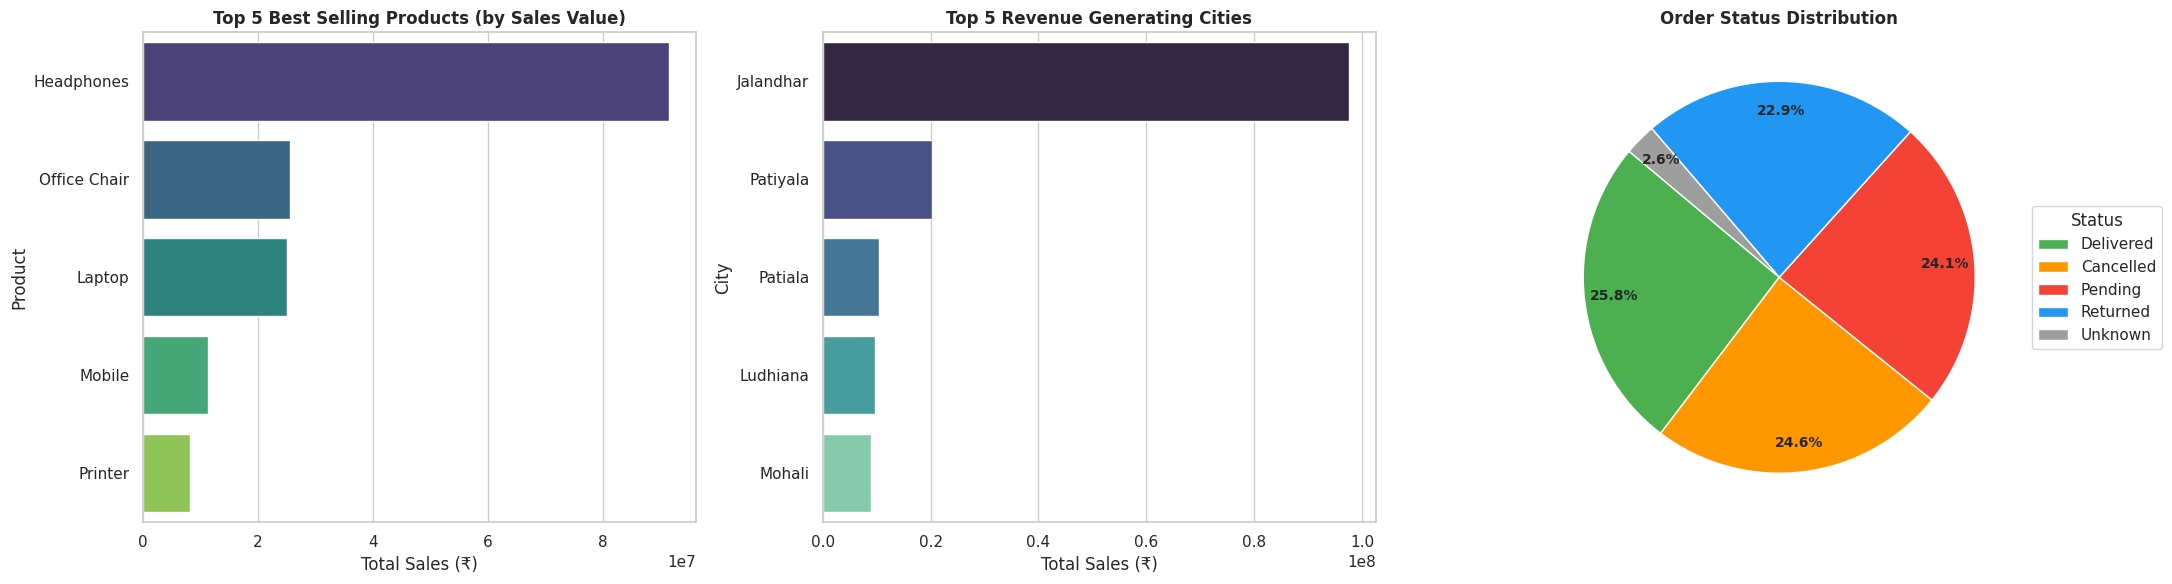

In [19]:
import matplotlib.pyplot as plt
import seaborn as sns
import pandas as pd

# Ensure clean copy is referenced correctly
data_to_plot = df_clean.copy()

# Clean up the 'Status' column to merge duplicates with bad spelling or casing
status_col = 'Status' if 'Status' in data_to_plot.columns else 'status'
data_to_plot[status_col] = data_to_plot[status_col].astype(str).str.strip().str.lower()

# Map inconsistent statuses to standardized names
status_mapping = {
    'delivered': 'Delivered',
    'delivred': 'Delivered',
    'pending': 'Pending',
    'pendng': 'Pending',
    'cancelled': 'Cancelled',
    'canceled': 'Cancelled',
    'returned': 'Returned',
    'unknown': 'Unknown',
    '-': 'Unknown'
}
data_to_plot[status_col] = data_to_plot[status_col].map(status_mapping).fillna('Unknown')

# Setup plot style
sns.set_theme(style="whitegrid")
fig, axes = plt.subplots(1, 3, figsize=(22, 6))

# 1. Top 5 Best Selling Products
top_p_df = data_to_plot.groupby('Product')['Total_Sales'].sum().sort_values(ascending=False).head(5).reset_index()
if not top_p_df.empty:
    sns.barplot(ax=axes[0], x='Total_Sales', y='Product', data=top_p_df, palette='viridis', hue='Product', legend=False)
axes[0].set_title('Top 5 Best Selling Products (by Sales Value)', fontsize=12, fontweight='bold')
axes[0].set_xlabel('Total Sales (₹)')
axes[0].set_ylabel('Product')

# 2. Top 5 Revenue Cities
city_col = 'City' if 'City' in data_to_plot.columns else 'city'
top_c_df = data_to_plot.groupby(city_col)['Total_Sales'].sum().sort_values(ascending=False).head(5).reset_index()
if not top_c_df.empty:
    sns.barplot(ax=axes[1], x='Total_Sales', y=city_col, data=top_c_df, palette='mako', hue=city_col, legend=False)
axes[1].set_title('Top 5 Revenue Generating Cities', fontsize=12, fontweight='bold')
axes[1].set_xlabel('Total Sales (₹)')
axes[1].set_ylabel('City')

# 3. Cleaned Order Status Distribution (Pie Chart)
status_counts = data_to_plot[status_col].value_counts()
if not status_counts.empty:
    # Using legend instead of overlapping labels on the pie slices
    wedges, texts, autotexts = axes[2].pie(
        status_counts,
        autopct='%1.1f%%',
        startangle=140,
        colors=['#4CAF50', '#FF9800', '#F44336', '#2196F3', '#9E9E9E'][:len(status_counts)],
        pctdistance=0.85
    )
    # Beautifully set legend on the side
    axes[2].legend(wedges, status_counts.index, title="Status", loc="center left", bbox_to_anchor=(1, 0, 0.5, 1))
    # Styling percentages inside pie
    plt.setp(autotexts, size=10, weight="bold")
else:
    axes[2].text(0.5, 0.5, 'No Status Data Available', ha='center', va='center')
axes[2].set_title('Order Status Distribution', fontsize=12, fontweight='bold')

plt.tight_layout()
plt.show()

In [17]:
import pandas as pd
import os

# ਫਾਈਲ ਦਾ ਸਹੀ ਰਸਤਾ ਚੈੱਕ ਕਰਨਾ
file_path = 'messy_data_2000_rows.xlsx'

if os.path.exists(file_path):
    # 1. ਲੋਡ ਕਰਨਾ
    df = pd.read_excel(file_path)
    print("✅ ਫਾਈਲ ਸਫਲਤਾਪੂਰਵਕ ਲੋਡ ਹੋ ਗਈ ਹੈ!")

    # 2. ਡੁਪਲੀਕੇਟ ਹਟਾਉਣਾ
    df_clean = df.drop_duplicates().copy()

    # 3. ਜ਼ਰੂਰੀ ਖਾਲੀ ਖਾਨੇ ਹਟਾਉਣਾ
    df_clean = df_clean.dropna(subset=['Order ID', 'Product'])

    # 4. ਡਾਟਾ ਕਿਸਮਾਂ (Data Types) ਨੂੰ ਸਹੀ ਕਰਨਾ
    df_clean['Order Date'] = pd.to_datetime(df_clean['Order Date'], dayfirst=True, errors='coerce')

    # ਆਟੋਮੈਟਿਕ ਸਹੀ ਕਾਲਮ ਲੱਭਣਾ
    qty_col = None
    for possible_name in ['Quantiy', 'Quantity', 'Quantitiy', 'qty']:
        if possible_name in df_clean.columns:
            qty_col = possible_name
            break

    if qty_col:
        df_clean['Quantity'] = pd.to_numeric(df_clean[qty_col], errors='coerce').fillna(0)
    else:
        df_clean['Quantity'] = 0

    df_clean['Unit Price'] = pd.to_numeric(df_clean['Unit Price'], errors='coerce')
    median_price = df_clean['Unit Price'].median() if not df_clean['Unit Price'].isnull().all() else 0
    df_clean['Unit Price'] = df_clean['Unit Price'].fillna(median_price)

    # 6. ਬਾਕੀ ਟੈਕਸਟ ਕਾਲਮਾਂ ਵਿੱਚ ਖਾਲੀ ਥਾਵਾਂ 'Unknown' ਭਰਨਾ
    text_cols = ['Customer Name', 'City', 'Category', 'Payment Method', 'Status', 'Phone', 'Email']
    for col in text_cols:
        if col in df_clean.columns:
            df_clean[col] = df_clean[col].fillna('Unknown')

    # 7. ਕੁੱਲ ਵਿਕਰੀ (Total Sales) ਦਾ ਨਵਾਂ ਕਾਲਮ ਬਣਾਉਣਾ
    df_clean['Total_Sales'] = df_clean['Quantity'] * df_clean['Unit Price']

    print("\n✅ ਡਾਟਾ ਪੂਰੀ ਤਰ੍ਹਾਂ ਸਾਫ਼ ਹੋ ਗਿਆ ਹੈ!")
    print(f"ਅਸਲ ਲਾਈਨਾਂ: {len(df)} -> ਸਾਫ਼ ਲਾਈਨਾਂ ਦੀ ਗਿਣਤੀ: {len(df_clean)}")
else:
    # ਜੇਕਰ ਫਾਈਲ ਕਿਸੇ ਹੋਰ ਫੋਲਡਰ ਵਿੱਚ ਅਪਲੋਡ ਹੋਈ ਹੋਵੇ
    uploaded_files = [f for f in os.listdir('.') if f.endswith('.xlsx')]
    if uploaded_files:
        actual_file = uploaded_files[0]
        print(f"✅ ਲੱਭੀ ਹੋਈ ਫਾਈਲ ਲੋਡ ਕੀਤੀ ਜਾ ਰਹੀ ਹੈ: {actual_file}")
        df = pd.read_excel(actual_file)
        df_clean = df.drop_duplicates().copy()
        df_clean = df_clean.dropna(subset=['Order ID', 'Product'])
        df_clean['Order Date'] = pd.to_datetime(df_clean['Order Date'], dayfirst=True, errors='coerce')
        df_clean['Quantity'] = pd.to_numeric(df_clean['Quantity'] if 'Quantity' in df_clean.columns else df_clean.get('Quantiy', 0), errors='coerce').fillna(0)
        df_clean['Unit Price'] = pd.to_numeric(df_clean['Unit Price'], errors='coerce').fillna(df_clean['Unit Price'].median() if 'Unit Price' in df_clean.columns else 0)

        text_cols = ['Customer Name', 'City', 'Category', 'Payment Method', 'Status', 'Phone', 'Email']
        for col in text_cols:
            if col in df_clean.columns:
                df_clean[col] = df_clean[col].fillna('Unknown')

        df_clean['Total_Sales'] = df_clean['Quantity'] * df_clean['Unit Price']
        print("\n✅ ਡਾਟਾ ਪੂਰੀ ਤਰ੍ਹਾਂ ਸਾਫ਼ ਹੋ ਗਿਆ ਹੈ!")
        print(f"ਸਾਫ਼ ਲਾਈਨਾਂ ਦੀ ਗਿਣਤੀ: {len(df_clean)}")
    else:
        print("❌ ਫਾਈਲ ਅਜੇ ਵੀ ਨਹੀਂ ਲੱਭੀ। ਕਿਰਪਾ ਕਰਕੇ ਉੱਪਰ ਦਿੱਤਾ ਅਪਲੋਡ ਵਾਲਾ ਕੋਡ (8a2428b1) ਦੁਬਾਰਾ ਚਲਾਓ।")

✅ ਫਾਈਲ ਸਫਲਤਾਪੂਰਵਕ ਲੋਡ ਹੋ ਗਈ ਹੈ!

✅ ਡਾਟਾ ਪੂਰੀ ਤਰ੍ਹਾਂ ਸਾਫ਼ ਹੋ ਗਿਆ ਹੈ!
ਅਸਲ ਲਾਈਨਾਂ: 2000 -> ਸਾਫ਼ ਲਾਈਨਾਂ ਦੀ ਗਿਣਤੀ: 1913


In [ ]:
import os
# Check the files in current directory
print(os.listdir('.'))

['.config', 'sample_data']
